# Finance News AI Analyzer

## Project Overview

This project explores how artificial intelligence can help users understand financial news. The application analyzes financial articles, identifies their sentiment, and uses a Large Language Model (LLM) to generate summaries and answer questions about the text.

The project combines traditional Natural Language Processing (NLP) techniques with generative AI to demonstrate how these technologies can support financial news analysis.

### Project Objectives
- Collect and organize sample financial news articles.
- Clean and preprocess financial text using Python.
- Identify positive, negative, or neutral sentiment.
- Classify articles into basic financial categories.
- Generate summaries and answer questions using an LLM.
- Create an interactive interface for users to analyze financial news.

**Disclaimer:** This application is for educational purposes only. It does not provide professional financial or investment advice.

## 1. Financial News Data Collection

For this project, I will begin with a small collection of fictional financial news examples. The articles cover topics such as company earnings, stock performance, banking, and economic conditions.

Each article includes an ID, publication date, source, topic, and text. I will use these examples to test the application's text processing and sentiment analysis features.

Users will also be able to enter their own financial news articles when the application is complete.


In [1]:
# Import libraries for working with financial news data
import pandas as pd
import re

# Pandas helps organize articles into a table.
# The re library will help clean text in later steps.

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

# Create a small sample of fictional financial news articles.
# These examples are for testing, not actual market reports.

news_data = [
    {
        "id": 1,
        "date": "2026-10-01",
        "source": "Sample Finance News",
        "topic": "Tech Stocks",
        "text": "A technology company reported strong quarterly earnings. Revenue increased by 25 percent, and profits exceeded analyst expectations. Investors responded positively to the announcement."
    },
    {
        "id": 2,
        "date": "2026-10-02",
        "source": "Sample Finance News",
        "topic": "Banking",
        "text": "A major bank reported a decline in quarterly profits. Rising loan defaults and increasing operating expenses created financial pressure. Analysts warned about possible future losses."
    },
    {
        "id": 3,
        "date": "2026-10-03",
        "source": "Sample Finance News",
        "topic": "Economy",
        "text": "The central bank announced that interest rates would remain unchanged. Economists expect inflation to slow gradually, while consumer spending remains stable."
    },
    {
        "id": 4,
        "date": "2026-10-04",
        "source": "Sample Finance News",
        "topic": "Investments",
        "text": "An investment company announced strong growth in its portfolio. Several stocks increased in value, and investors expressed confidence in future market performance."
    },
    {
        "id": 5,
        "date": "2026-10-05",
        "source": "Sample Finance News",
        "topic": "Retail",
        "text": "A retail company reported falling sales during the latest quarter. Higher product prices reduced customer demand, and management expects continued challenges."
    },
    {
        "id": 6,
        "date": "2026-10-06",
        "source": "Sample Finance News",
        "topic": "Energy",
        "text": "An energy company announced plans to expand its renewable energy projects. The investment could create new jobs, but high construction costs may reduce short-term profits."
    }
]

# Convert the articles into a Pandas DataFrame.
df = pd.DataFrame(news_data)

# Display the dataset.
display(df)


,id,date,source,topic,text
0,1,2026-10-01,Sample Finance News,Tech Stocks,A technology company reported strong quarterly...
1,2,2026-10-02,Sample Finance News,Banking,A major bank reported a decline in quarterly p...
2,3,2026-10-03,Sample Finance News,Economy,The central bank announced that interest rates...
3,4,2026-10-04,Sample Finance News,Investments,An investment company announced strong growth ...
4,5,2026-10-05,Sample Finance News,Retail,A retail company reported falling sales during...
5,6,2026-10-06,Sample Finance News,Energy,An energy company announced plans to expand it...


In [3]:
# Check the number of articles and columns.
print("Dataset shape:", df.shape)

# Check whether any columns contain missing values.
print("\nMissing values:")
print(df.isnull().sum())

# Display the financial topics included in the dataset.
print("\nAvailable topics:")
print(df["topic"].unique())

Dataset shape: (6, 5)

Missing values:
id        0
date      0
source    0
topic     0
text      0
dtype: int64

Available topics:
['Tech Stocks' 'Banking' 'Economy' 'Investments' 'Retail' 'Energy']


### Data Collection Summary

I created a small dataset containing six fictional financial news articles to test the first version of my application. The articles cover different financial topics and include examples of positive, negative, and mixed financial developments.

I used Pandas to organize the data and checked for missing values before continuing. The dataset does not contain real market information, so it is useful for demonstrating the application's features without relying on live financial news.

In the next step, I will prepare the article text for NLP analysis by removing unnecessary characters, converting text to lowercase, and separating it into individual words.


## 2. Financial Text Preprocessing

Before analyzing financial news, I need to prepare the text so the application can process it more consistently.

In this step, I will use basic Natural Language Processing (NLP) techniques to clean and organize the articles. These techniques include:

- **Text Cleaning:** Removing URLs, HTML tags, and unnecessary characters.
- **Lowercasing:** Converting words to lowercase for consistency.
- **Tokenization:** Splitting text into individual words.
- **Word Count:** Measuring the number of words in each article.

I will keep the original text because the language model will need the complete articles to generate summaries and answer questions. The cleaned text will help with basic NLP analysis.

Unlike traditional NLP models, modern Large Language Models (LLMs) usually handle their own tokenization and do not require this type of manual cleaning.

In [4]:
# Create a function to clean financial news text.
def clean_text(text):
    # Convert the input into a string.
    text = str(text)

    # Remove HTML tags if they appear in an article.
    text = re.sub(r'<[^>]+>', ' ', text)

    # Remove website links.
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Convert the text to lowercase.
    text = text.lower()

    # Remove unnecessary characters.
    # Keep letters, numbers, percent signs, and basic punctuation.
    text = re.sub(r'[^a-z0-9\s%.,!?$+-]', ' ', text)

    # Remove extra spaces between words.
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Test the function using a sample financial headline.
sample_text = "Company ABC's revenue increased by 25%! Visit https://example.com"

print("Original Text:")
print(sample_text)

print("\nCleaned Text:")
print(clean_text(sample_text))

Original Text:
Company ABC's revenue increased by 25%! Visit https://example.com

Cleaned Text:
company abc s revenue increased by 25%! visit


In [5]:
# Apply the cleaning function to every financial article.
df["cleaned_text"] = df["text"].apply(clean_text)

# Compare the original articles with their cleaned versions.
print("Original and Cleaned Financial News:")

display(df[["id", "text", "cleaned_text"]])

Original and Cleaned Financial News:


,id,text,cleaned_text
0,1,A technology company reported strong quarterly...,a technology company reported strong quarterly...
1,2,A major bank reported a decline in quarterly p...,a major bank reported a decline in quarterly p...
2,3,The central bank announced that interest rates...,the central bank announced that interest rates...
3,4,An investment company announced strong growth ...,an investment company announced strong growth ...
4,5,A retail company reported falling sales during...,a retail company reported falling sales during...
5,6,An energy company announced plans to expand it...,an energy company announced plans to expand it...


### 2.1 Tokenization and Word Count

Tokenization is the process of dividing text into smaller units called tokens. For this step, I will use a simple word-based approach to separate each financial article into individual words.

After tokenizing the articles, I will calculate their word counts to understand the size of the text samples.

This basic tokenization is useful for exploring the dataset. However, language models use their own tokenizers, which can divide text into words, parts of words, or other units.

In [6]:
# Create a function to split cleaned text into words.
def tokenize_text(text):
    return text.split()


# Apply tokenization to all cleaned articles.
df["tokens"] = df["cleaned_text"].apply(tokenize_text)

# Count the number of tokens in each article.
df["word_count"] = df["tokens"].apply(len)

# Display the article ID, topic, tokens, and word count.
display(df[["id", "topic", "tokens", "word_count"]])

# Calculate basic statistics about article lengths.
print("Total articles:", len(df))
print("Average word count:", round(df["word_count"].mean(), 2))
print("Longest article:", df["word_count"].max(), "words")
print("Shortest article:", df["word_count"].min(), "words")

,id,topic,tokens,word_count
0,1,Tech Stocks,"[a, technology, company, reported, strong, qua...",23
1,2,Banking,"[a, major, bank, reported, a, decline, in, qua...",25
2,3,Economy,"[the, central, bank, announced, that, interest...",21
3,4,Investments,"[an, investment, company, announced, strong, g...",22
4,5,Retail,"[a, retail, company, reported, falling, sales,...",21
5,6,Energy,"[an, energy, company, announced, plans, to, ex...",25


Total articles: 6
Average word count: 22.83
Longest article: 25 words
Shortest article: 21 words


In [7]:
# Select the columns needed for future analysis.
processed_df = df[
    ["id", "date", "source", "topic",
     "text", "cleaned_text", "word_count"]
].copy()

# Save the cleaned dataset to a CSV file.
processed_df.to_csv(
    "financial_news_processed.csv",
    index=False
)

print("Preprocessed dataset saved successfully!")

# Preview the saved dataset.
display(processed_df.head())

Preprocessed dataset saved successfully!


,id,date,source,topic,text,cleaned_text,word_count
0,1,2026-10-01,Sample Finance News,Tech Stocks,A technology company reported strong quarterly...,a technology company reported strong quarterly...,23
1,2,2026-10-02,Sample Finance News,Banking,A major bank reported a decline in quarterly p...,a major bank reported a decline in quarterly p...,25
2,3,2026-10-03,Sample Finance News,Economy,The central bank announced that interest rates...,the central bank announced that interest rates...,21
3,4,2026-10-04,Sample Finance News,Investments,An investment company announced strong growth ...,an investment company announced strong growth ...,22
4,5,2026-10-05,Sample Finance News,Retail,A retail company reported falling sales during...,a retail company reported falling sales during...,21


### Text Preprocessing Summary

In this step, I prepared the financial news dataset for further analysis. I created a Python function to clean the articles by removing unnecessary characters, website links, and extra spaces. I also converted the text to lowercase while keeping important financial information such as numbers and percentages.

Next, I separated the cleaned articles into words and calculated their word counts. This allowed me to examine the length of the articles and understand how the text was organized. I saved the processed dataset as a CSV file so I could reuse it in later steps.

I kept the original articles because the language model will need their complete context for summaries and questions. In the next step, I will use traditional NLP to calculate sentiment scores and then connect a language model to provide more detailed financial insights.

## 3. Financial Sentiment Analysis Using FinBERT

In this step, I will use FinBERT, a pretrained language model designed for financial sentiment analysis.

Unlike a simple keyword-based approach, FinBERT examines the context of financial text to predict whether an article has positive, negative, or neutral sentiment.

For this project, I will use the pretrained `ProsusAI/finbert` model from Hugging Face. This allows me to experiment with a language model without having to train one from scratch.

The model will provide:
- A predicted sentiment label (positive, negative, or neutral).
- A confidence score for the predicted sentiment.

I will use these results to examine how the model interprets different types of financial news.

FinBERT is a language model specialized for classification. Later, I will integrate a generative language model to summarize financial news and answer questions.

In [8]:
# Install the libraries needed to run FinBERT.
# Transformers provides access to pretrained language models.
# PyTorch supports the model's computations.

!pip -q install transformers torch

In [9]:
# Import the Hugging Face pipeline function.
from transformers import pipeline

# Load the pretrained FinBERT sentiment analysis model.
# The model already knows how to classify financial text.
finbert = pipeline(
    task="text-classification",
    model="ProsusAI/finbert"
)

print("FinBERT model loaded successfully!")

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

FinBERT model loaded successfully!


In [10]:
# Select the first financial news article.
sample_article = df["text"].iloc[0]

# Let FinBERT analyze the article.
sample_result = finbert(sample_article)

# Display the original article and its prediction.
print("Financial News Article:")
print(sample_article)

print("\nFinBERT Prediction:")
print(sample_result)

Financial News Article:
A technology company reported strong quarterly earnings. Revenue increased by 25 percent, and profits exceeded analyst expectations. Investors responded positively to the announcement.

FinBERT Prediction:
[{'label': 'positive', 'score': 0.9552544355392456}]


In [11]:
# Send all financial articles to FinBERT.
# The model predicts sentiment for each article.

articles = df["text"].tolist()

sentiment_results = finbert(
    articles,
    truncation=True,
    batch_size=8
)

# Convert the model's predictions into a DataFrame.
sentiment_df = pd.DataFrame(sentiment_results)

# Add the predicted labels and confidence scores.
df["sentiment"] = sentiment_df["label"]
df["confidence"] = sentiment_df["score"]

# Display the results for all articles.
display(
    df[["id", "topic", "sentiment", "confidence"]]
)

,id,topic,sentiment,confidence
0,1,Tech Stocks,positive,0.955254
1,2,Banking,negative,0.973863
2,3,Economy,positive,0.480419
3,4,Investments,positive,0.949476
4,5,Retail,negative,0.972972
5,6,Energy,negative,0.732166


### 3.1 Understanding FinBERT Predictions

FinBERT predicts one of three sentiment categories:

- **Positive:** Financial information that suggests favorable developments.
- **Negative:** Financial information that suggests unfavorable developments.
- **Neutral:** Financial information that does not strongly suggest either positive or negative developments.

The confidence score shows how strongly the model favors its predicted category. However, a high confidence score does not guarantee that the prediction is correct.

Financial articles may contain both positive and negative information. In these cases, the model selects the category that best matches its interpretation of the overall text.

Since I am using a pretrained model without labeled test data, I will examine its predictions rather than claim a measured accuracy score.

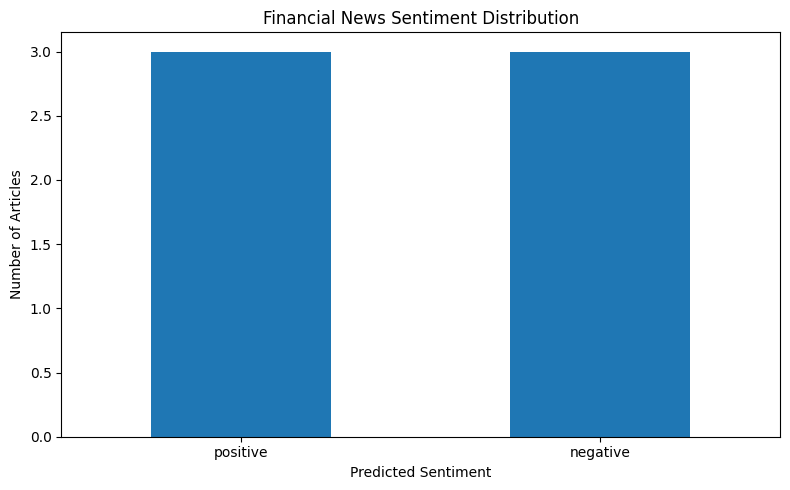

In [12]:
# Import Matplotlib for data visualization.
import matplotlib.pyplot as plt

# Count the number of articles in each sentiment category.
sentiment_counts = df["sentiment"].value_counts()

# Create a bar chart of the model's predictions.
plt.figure(figsize=(8, 5))

sentiment_counts.plot(kind="bar")

# Add a title and axis labels.
plt.title("Financial News Sentiment Distribution")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Number of Articles")

# Keep category labels easy to read.
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [13]:
# Select the columns needed for our final application.
sentiment_output = df[
    ["id", "date", "source", "topic",
     "text", "cleaned_text",
     "sentiment", "confidence"]
].copy()

# Save the model predictions to a CSV file.
sentiment_output.to_csv(
    "financial_news_sentiment.csv",
    index=False
)

print("Financial sentiment results saved successfully!")

display(sentiment_output)

Financial sentiment results saved successfully!


,id,date,source,topic,text,cleaned_text,sentiment,confidence
0,1,2026-10-01,Sample Finance News,Tech Stocks,A technology company reported strong quarterly...,a technology company reported strong quarterly...,positive,0.955254
1,2,2026-10-02,Sample Finance News,Banking,A major bank reported a decline in quarterly p...,a major bank reported a decline in quarterly p...,negative,0.973863
2,3,2026-10-03,Sample Finance News,Economy,The central bank announced that interest rates...,the central bank announced that interest rates...,positive,0.480419
3,4,2026-10-04,Sample Finance News,Investments,An investment company announced strong growth ...,an investment company announced strong growth ...,positive,0.949476
4,5,2026-10-05,Sample Finance News,Retail,A retail company reported falling sales during...,a retail company reported falling sales during...,negative,0.972972
5,6,2026-10-06,Sample Finance News,Energy,An energy company announced plans to expand it...,an energy company announced plans to expand it...,negative,0.732166


### Sentiment Analysis Summary

In this step, I used the pretrained FinBERT language model to analyze financial news sentiment. Instead of creating manual keyword rules, I let the model examine the text and predict whether each article was positive, negative, or neutral.

I first tested FinBERT on one article and then applied it to the entire dataset. The model returned sentiment labels and confidence scores, which I organized into a Pandas DataFrame. I also created a bar chart to visualize the distribution of predicted sentiment categories.

This step showed me how a pretrained language model can perform financial text classification without additional training. However, the predictions may not always reflect the full meaning of an article, especially when it contains mixed financial information.

In the next step, I will integrate a generative language model to summarize articles, identify financial risks, and answer user questions based on the provided text.

## 4. Generative AI Integration Using Qwen

In this step, I will integrate Qwen2.5-1.5B-Instruct, a pretrained Small Language Model (SLM), into my Finance News AI Analyzer.

Unlike FinBERT, which classifies financial sentiment, Qwen can generate text responses based on instructions and financial articles.

I will use Qwen for three features:

- **Financial News Summarization:** Generate short summaries of articles.
- **Risk and Opportunity Analysis:** Identify financial risks and opportunities mentioned in the text.
- **Question Answering:** Answer user questions based on financial articles.

I chose a small open-source model because it can run directly in Google Colab without requiring an external API key.

The model will generate responses rather than using manually written answers. However, its output may contain mistakes or unsupported information, so users should verify important financial details.

**Disclaimer:** This project is for educational purposes only and does not provide professional financial advice.

In [14]:
# Install the libraries needed to run the language model.
# Transformers loads the pretrained model and tokenizer.
# Accelerate helps manage model execution in Colab.

%pip install -q -U transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 62.7 MB/s eta 0:00:00


In [15]:
# Import libraries for running the language model.
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# Use a larger Qwen model for more reliable financial responses.
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

# Load the tokenizer for the selected model.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Select GPU if available, otherwise use CPU.
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load the pretrained language model.
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16 if device == "cuda" else torch.float32,
    low_cpu_mem_usage=True
).to(device)

model.eval()

print("Qwen model loaded successfully!")
print("Running on:", device)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen model loaded successfully!
Running on: cuda


### 4.1 Generating Responses with Qwen

After loading the pretrained model, I will create a function that allows Qwen to process financial articles and generate responses.

The function will prepare instructions for the model, convert them into tokens, and generate new text.

I will use the same function for financial news summarization, risk analysis, and question answering. The model will generate its own responses based on the information provided.

Since Qwen2.5-1.5B-Instruct is a relatively small language model, its responses may be less accurate or detailed than those of larger models.

In [16]:
# Generate financial responses using the Qwen language model.
def generate_ai_response(article_text, task_instruction):

    # Prepare the system instructions.
    messages = [
        {
            "role": "system",
            "content": (
                "You are a careful financial news analysis assistant. "
                "Your job is to analyze only the financial article provided. "
                "Never invent people, company names, numbers, financial risks, "
                "or events that are not supported by the article. "
                "If information is missing, explain that the article "
                "does not provide enough information. "
                "Do not provide investment advice. "
                "Keep answers brief and factual."
            )
        },
        {
            "role": "user",
            "content": (
                "Use the article below as your only source of factual information.\n\n"
                f"<article>\n{article_text}\n</article>\n\n"
                f"Task: {task_instruction}\n\n"
                "Do not add unsupported details."
            )
        }
    ]

    # Convert the messages into model input tensors.
    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(device)

    # Generate a response.
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            repetition_penalty=1.1,
            pad_token_id=tokenizer.eos_token_id
        )

    # Extract only the newly generated text.
    generated_tokens = outputs[0][
        inputs["input_ids"].shape[-1]:
    ]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response.strip()

In [17]:
# Select the first financial news article.
article = df["text"].iloc[0]

# Ask Qwen to summarize the financial information.
summary = generate_ai_response(
    article,
    "Summarize this financial article in 2-3 simple sentences. "
    "Include the most important financial details."
)

print("Original Article:")
print(article)

print("\nQwen Summary:")
print(summary)

Original Article:
A technology company reported strong quarterly earnings. Revenue increased by 25 percent, and profits exceeded analyst expectations. Investors responded positively to the announcement.

Qwen Summary:
The tech company saw its revenue rise by 25% and beat profit forecasts, leading investors to react favorably.


### 4.2 Financial Risk and Opportunity Analysis

In this part, I will use Qwen to identify potential financial risks and opportunities from an article.

Instead of creating manual rules to identify financial risks, I will provide the article and ask the language model to interpret its content.

The model should explain which developments could represent risks or opportunities based on the provided information.

The results are intended to demonstrate AI-generated financial insights rather than provide investment recommendations.

In [18]:
# Select an article about renewable energy expansion.
risk_article = df["text"].iloc[5]

# Ask Qwen to identify risks and opportunities.
risk_analysis = generate_ai_response(
    risk_article,
    "Identify the main financial risks and opportunities "
    "mentioned in this article. Explain them briefly. "
    "Do not add information that is not in the text."
)

print("Financial Article:")
print(risk_article)

print("\nAI Risk and Opportunity Analysis:")
print(risk_analysis)

Financial Article:
An energy company announced plans to expand its renewable energy projects. The investment could create new jobs, but high construction costs may reduce short-term profits.

AI Risk and Opportunity Analysis:
Main Financial Risks:
- High construction costs may reduce short-term profits.

Main Financial Opportunities:
- Expansion of renewable energy projects could create new jobs.


### 4.3 Financial Question Answering

Another important feature of the application is financial question answering.

Users will be able to ask their own questions about financial articles instead of choosing from predefined answers.

I will create a function that sends the financial article and the user's question to Qwen.

The model will generate a response based on the article. If the article does not contain enough information, the model should explain that limitation.

This feature demonstrates how an SLM can make financial information easier to explore through natural language.

In [19]:
# Create a function to answer questions about financial articles.
def ask_financial_question(article_text, question):

    # Send the article and question to Qwen.
    return generate_ai_response(
        article_text,
        f"Answer this question using only the article: {question}"
    )


# Select the banking article.
qa_article = df["text"].iloc[1]

# Example question for testing.
question = "Why did the bank experience financial difficulties?"

# Generate the answer.
answer = ask_financial_question(qa_article, question)

print("Question:")
print(question)

print("\nQwen Answer:")
print(answer)

Question:
Why did the bank experience financial difficulties?

Qwen Answer:
The bank experienced financial difficulties due to rising loan defaults and increasing operating expenses.


### Small Language Model Integration Summary

In this step, I integrated Qwen2.5-0.5B-Instruct into my Finance News AI Analyzer. I chose this open-source Small Language Model because I could run it directly in Google Colab without using an external API key.

I created a reusable text generation function that sends financial articles and instructions to the model. I then tested three different tasks: financial news summarization, risk and opportunity analysis, and question answering. Unlike a manually programmed system, Qwen generated its responses from the input text.

This experiment helped me understand the difference between a classification model and a generative language model. FinBERT predicts financial sentiment, while Qwen can produce explanations and respond to questions. However, the smaller model may misunderstand information or generate inaccurate details, so its responses still require careful review.

In the next step, I will combine both models into a single interactive application.

## 5. Building the Interactive Finance News AI Analyzer

In this step, I will combine the FinBERT sentiment model and the Qwen language model into a single application using Gradio.

Gradio allows me to create an interactive interface using Python without writing separate HTML or JavaScript files.

The application will allow users to:

- Select one of the sample financial articles or enter their own text.
- Analyze financial sentiment using FinBERT.
- View the predicted sentiment and confidence scores.
- Generate a financial news summary using Qwen.
- Identify potential financial risks and opportunities.
- Ask questions about the article and receive AI-generated answers.

The application will not rely on manually programmed financial classifications or responses. Instead, the pretrained models will process the user's input.

This prototype demonstrates how financial analysts or news platforms could use AI to review financial news more efficiently.

In [20]:
# Install Gradio to create our interactive application.
%pip install -q -U gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 6.0 MB/s eta 0:00:00


In [21]:
# Import Gradio for creating the interface.
import gradio as gr

# Create dropdown labels using the existing dataset.
article_choices = {
    f"Article {row['id']} - {row['topic']}": row["text"]
    for _, row in df.iterrows()
}

# Create a function that retrieves the selected article.
def select_article(article_name):

    # Return the article corresponding to the selected name.
    return article_choices.get(article_name, "")


print("Gradio imported successfully!")
print("Available sample articles:", len(article_choices))

Gradio imported successfully!
Available sample articles: 6


### 5.1 Connecting FinBERT and Qwen to the Interface

The application will use two different pretrained models to analyze financial news.

FinBERT will predict financial sentiment and return confidence scores for positive, negative, and neutral categories.

Qwen will handle generative AI tasks, including summarization, financial risk analysis, and question answering.

I will create Python functions that connect these models to the Gradio interface. These functions will process the user's input and return the actual model results without manually assigning sentiment labels or writing predefined answers.

In [22]:
# Analyze a financial article using FinBERT and Qwen.
def analyze_article(article_text):

    # Make sure the user entered an article.
    if not article_text or not article_text.strip():
        return (
            "Please enter a financial article.",
            "",
            "",
            ""
        )

    # Ask FinBERT to predict all three sentiment probabilities.
    predictions = finbert(
        article_text,
        truncation=True,
        top_k=None
    )

    # Organize the model's sentiment results.
    sentiment_scores = {
        result["label"]: result["score"]
        for result in predictions
    }

    # Find the sentiment with the highest model score.
    predicted_sentiment = max(
        sentiment_scores,
        key=sentiment_scores.get
    )

    confidence = sentiment_scores[predicted_sentiment]

    # Format the FinBERT prediction for the interface.
    sentiment_result = (
        f"Predicted Sentiment: {predicted_sentiment.title()}\n"
        f"Confidence: {confidence:.2%}"
    )

    # Display the individual probabilities.
    score_details = "\n".join(
        f"{label.title()}: {score:.2%}"
        for label, score in sentiment_scores.items()
    )

    # Ask Qwen to summarize the financial article.
    summary = generate_ai_response(
        article_text,
        "Summarize this financial article in 2-3 sentences. "
        "Focus on the most important financial details."
    )

    # Ask Qwen to identify risks and opportunities.
    risk_analysis = generate_ai_response(
        article_text,
        "Identify the main financial risks and opportunities "
        "mentioned in this article. Explain them briefly "
        "without inventing information."
    )

    return (
        sentiment_result,
        score_details,
        summary,
        risk_analysis
    )


# Answer user questions using Qwen.
def answer_question(article_text, question):

    # Check that the article and question are provided.
    if not article_text or not article_text.strip():
        return "Please enter a financial article first."

    if not question or not question.strip():
        return "Please enter a question."

    # Generate the answer using our existing Qwen function.
    answer = ask_financial_question(
        article_text,
        question
    )

    return answer


print("Application functions created successfully!")

Application functions created successfully!


### 5.2 Designing the Gradio Interface

For the user interface, I will organize the application into separate sections for financial news input, sentiment analysis, AI-generated insights, and question answering.

Users will be able to select a sample article or paste their own financial text. After clicking the analysis button, the application will display FinBERT's sentiment prediction and Qwen's generated summary and risk analysis.

A separate question box will allow users to ask questions about the article.

The interface will include a disclaimer explaining that the application is an educational prototype and should not replace professional financial advice.

In [23]:
# Build the complete Finance News AI Analyzer interface.
with gr.Blocks(
    title="Finance News AI Analyzer"
) as demo:

    # Application title and description.
    gr.Markdown(
        """
        # Finance News AI Analyzer

        Analyze financial news using two pretrained AI models:
        **FinBERT** for sentiment analysis and **Qwen** for
        financial summaries, risk analysis, and question answering.

        This application is an educational prototype.
        """
    )

    # Section 1: Financial News Input
    gr.Markdown("## 1. Financial News Input")

    article_dropdown = gr.Dropdown(
        choices=list(article_choices.keys()),
        label="Select a Sample Article",
        value=None
    )

    article_input = gr.Textbox(
        label="Financial News Article",
        placeholder="Select a sample article or paste your own financial news here...",
        lines=8
    )

    # Fill the text box when a sample article is selected.
    article_dropdown.change(
        fn=select_article,
        inputs=article_dropdown,
        outputs=article_input
    )

    # Button to start the analysis.
    analyze_button = gr.Button(
        "Analyze Financial News",
        variant="primary"
    )

    # Section 2: Sentiment Results
    gr.Markdown("## 2. Financial Sentiment Analysis")

    with gr.Row():

        sentiment_output = gr.Textbox(
            label="FinBERT Sentiment Prediction",
            lines=3
        )

        confidence_output = gr.Textbox(
            label="Sentiment Probability Scores",
            lines=4
        )

    # Section 3: AI Summaries and Risk Analysis
    gr.Markdown("## 3. AI-Generated Financial Insights")

    summary_output = gr.Textbox(
        label="Qwen Financial News Summary",
        lines=5
    )

    risk_output = gr.Textbox(
        label="Qwen Risk and Opportunity Analysis",
        lines=7
    )

    # Connect the analysis button to both AI models.
    analyze_button.click(
        fn=analyze_article,
        inputs=article_input,
        outputs=[
            sentiment_output,
            confidence_output,
            summary_output,
            risk_output
        ]
    )

    # Section 4: Financial Questions
    gr.Markdown("## 4. Ask Questions About the Article")

    question_input = gr.Textbox(
        label="Your Financial Question",
        placeholder="What are the main financial risks?",
        lines=2
    )

    question_button = gr.Button(
        "Ask Qwen"
    )

    answer_output = gr.Textbox(
        label="AI-Generated Answer",
        lines=6
    )

    # Connect the question button to Qwen.
    question_button.click(
        fn=answer_question,
        inputs=[
            article_input,
            question_input
        ],
        outputs=answer_output
    )

    # Display the educational disclaimer.
    gr.Markdown(
        """
        ---
        **Disclaimer:** This application is for educational
        and informational purposes only. AI-generated
        responses may contain inaccuracies. This tool
        does not provide professional financial advice.
        """
    )

print("Gradio interface created successfully!")

Gradio interface created successfully!


In [24]:
# Quick diagnostic: test the application with Article 1 before launching Gradio.
# This uses your real FinBERT and Qwen functions, not hard-coded answers.
print("Device used by Qwen:", device, flush=True)
print("Testing Article 1...", flush=True)
test_article = df["text"].iloc[0]
print("Article text:", test_article, flush=True)

# Run the same pipeline connected to the Gradio Analyze button.
results = analyze_article(test_article)

for label, value in zip(
    ["FinBERT Sentiment", "Sentiment Scores", "Qwen Summary", "Qwen Risk Analysis"],
    results
):
    print(f"\n--- {label} ---", flush=True)
    print(value, flush=True)


Device used by Qwen: cuda
Testing Article 1...
Article text: A technology company reported strong quarterly earnings. Revenue increased by 25 percent, and profits exceeded analyst expectations. Investors responded positively to the announcement.

--- FinBERT Sentiment ---
Predicted Sentiment: Positive
Confidence: 95.53%

--- Sentiment Scores ---
Positive: 95.53%
Neutral: 2.71%
Negative: 1.76%

--- Qwen Summary ---
The technology company reported robust quarterly earnings with revenue up 25% and profit surpassing analyst forecasts. This positive performance led to investor enthusiasm following the announcement.

--- Qwen Risk Analysis ---
The article mentions no specific financial risks or opportunities. It focuses on positive aspects such as revenue growth and profit exceeding expectations, indicating investor satisfaction with the company's performance.


In [25]:
# Launch the interactive Gradio application.
# The interface will run using our Colab environment.

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2ea555b77c058abf53.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### 5.3 Testing the Application

After creating the Gradio interface, I will test the application using different financial articles.

My testing will focus on the following features:

1. **Sample Article Selection:** Confirm that selecting a sample article automatically fills the article text box.
2. **Sentiment Analysis:** Check whether FinBERT returns sentiment predictions and confidence scores.
3. **AI Summarization:** Examine whether Qwen generates a summary based on the article.
4. **Risk Analysis:** Check whether Qwen identifies financial risks and opportunities supported by the article.
5. **Question Answering:** Ask different questions and evaluate whether the model provides relevant answers.
6. **Custom Article Input:** Paste a new financial article to test whether the application handles information outside the original dataset.

I will review the generated results for relevance, clarity, and possible inaccuracies. The goal is to demonstrate a working application rather than claim that the models always produce correct financial analysis.


## 6. Business Use Case and Project Reflection

### Business Use Case

Financial analysts and financial news platforms often need to review large amounts of information. My Finance News AI Analyzer demonstrates how AI could help organize and interpret this information more efficiently.

FinBERT can provide an initial sentiment assessment, while Qwen can generate summaries, identify possible financial risks, and answer questions about specific articles. These features could help analysts quickly review news before performing more detailed research.

### Limitations

The application has several limitations. FinBERT's sentiment predictions may not always reflect the full meaning of an article. Qwen is a relatively small language model, so it may generate inaccurate explanations or overlook important details.

The application does not access live stock prices or verify news against external sources. It also cannot predict market movements reliably or replace professional financial analysis.

### Project Reflection

This project helped me explore how different language models can work together in one application. I used FinBERT for financial sentiment classification and Qwen for generative AI tasks. I connected both models to Gradio so users could interact with them through a simple interface.

I learned more about pretrained models, prompt design, and connecting AI functions to an application. I also saw why testing is important when working with generative AI, since a model can produce responses that sound convincing but may not be fully accurate.

Overall, this project gave me practical experience building an AI application for the finance sector.
